# Агрегация: not/mixed × small/big

Четыре независимые кривые: **big/mixed, small/mixed, big/not, small/not**. На оси X только четыре четверти относительной глубины. Отдельных моделей на итоговых графиках нет; датасеты и размерные группы не усредняются друг с другом.

**Полные сохранённые результаты: все слои, оба датасета, пять pair-wise fold.**
Переоценка замороженных весов из checkpoint2; новая оптимизация не выполнялась. Происхождение весов и проверки центров записаны в `source_validation.json`.
Результаты: `results/saved_full/`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import torch
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "modules/experiments.py").exists())
sys.path.insert(0, str(REPO_ROOT))
from modules.experiments import collect, CASES
from modules import plots


In [2]:
OUTPUT_ROOT = REPO_ROOT / "results/saved_full"
REQUIRE_COMPLETE = True  # False only for explicit partial/smoke inspection
PLOT_SPLITS = ("test",)  # add "train" for separate train panels

ERROR! Session/line number was not unique in database. History logging moved to new session 12


## Покрытие и параметры

Полная агрегация требует обеих секций всех пяти моделей, всех слоёв и всех fold. В partial-режиме неполные срезы подписываются. Смешивание разных конфигураций обучения запрещено.

In [3]:
long, depth, coverage = collect(OUTPUT_ROOT, require_complete=REQUIRE_COMPLETE)
display(coverage)
if not coverage.full_hyperparameters.all() or not coverage.complete_layers.all():
    print("SMOKE / PARTIAL: these are not full experiment results")

,dataset,model,protocol,available,full_hyperparameters,complete_layers,config_json
0,not,gemma-2-2b,rowwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
1,not,gemma-2-2b,pairwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
2,not,gemma-2-2b-it,rowwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
3,not,gemma-2-2b-it,pairwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
4,not,gemma-2-9b,rowwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
5,not,gemma-2-9b,pairwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
6,not,gemma-2-9b-it,rowwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
7,not,gemma-2-9b-it,pairwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
8,not,deberta-hate-tuned,rowwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."
9,not,deberta-hate-tuned,pairwise,True,True,True,"{""device"": ""cpu"", ""epochs"": 1500, ""lr"": 0.015,..."


## Относительная глубина и веса

`relative_depth = layer / (n_layers - 1)`; embedding — слой 0. Четверти: [0, 25%], (25%, 50%], (50%, 75%], (75%, 100%].

Внутри каждого fold сначала усредняются слои модели в четверти, затем модели с равными весами внутри dataset/size. После этого вычисляются среднее и std групповых средних по fold. У каждой модели равный вес. Small: Gemma 2B/2B IT и DeBERTa; big: Gemma 9B/9B IT. `std` — разброс групповых средних по пяти fold (ddof=1), не доверительный интервал. Для row-wise нет полосы fold std. Цвет задаёт датасет: mixed синий, not оранжевый; big — сплошная линия, small — пунктир. Протоколы, split, калибровка и PA-варианты никогда не усредняются друг с другом.

In [4]:
for dataset in ("not", "mixed"):
    for size in ("small", "big"):
        print(dataset, size)
        display(depth.loc[depth.dataset.eq(dataset) & depth["size"].eq(size)])

not small
not big
mixed small
mixed big


,dataset,size,protocol,split,calibration,metric,depth,mean,model_std,n_models,expected_models,complete,std,n_folds
1152,not,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Early,0.226971,0.053568,3,3,True,0.006862,5
1153,not,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-early,0.291448,0.042394,3,3,True,0.016202,5
1154,not,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-late,0.177644,0.124195,3,3,True,0.011075,5
1155,not,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Late,0.121479,0.077797,3,3,True,0.016062,5
1156,not,small,pairwise,test,baseline_alignment,behavioral_accuracy,Early,0.560800,0.104617,3,3,True,0.008359,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1531,not,small,rowwise,train,reference,esa,Late,0.556548,0.020715,3,3,True,NaN,1
1532,not,small,rowwise,train,reference,pc,Early,0.182400,0.156743,3,3,True,NaN,1
1533,not,small,rowwise,train,reference,pc,Middle-early,0.069172,0.041296,3,3,True,NaN,1
1534,not,small,rowwise,train,reference,pc,Middle-late,0.061842,0.047391,3,3,True,NaN,1


,dataset,size,protocol,split,calibration,metric,depth,mean,model_std,n_models,expected_models,complete,std,n_folds
768,not,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Early,0.271855,0.107377,2,2,True,0.009136,5
769,not,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-early,0.288873,0.061608,2,2,True,0.025279,5
770,not,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-late,0.107240,0.113194,2,2,True,0.016815,5
771,not,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Late,0.094836,0.088555,2,2,True,0.011957,5
772,not,big,pairwise,test,baseline_alignment,behavioral_accuracy,Early,0.666000,0.216658,2,2,True,0.016000,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,not,big,rowwise,train,reference,esa,Late,0.596546,0.013456,2,2,True,NaN,1
1148,not,big,rowwise,train,reference,pc,Early,0.243503,0.031630,2,2,True,NaN,1
1149,not,big,rowwise,train,reference,pc,Middle-early,0.102021,0.015502,2,2,True,NaN,1
1150,not,big,rowwise,train,reference,pc,Middle-late,0.113720,0.066106,2,2,True,NaN,1


,dataset,size,protocol,split,calibration,metric,depth,mean,model_std,n_models,expected_models,complete,std,n_folds
384,mixed,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Early,0.175751,0.072387,3,3,True,0.013752,5
385,mixed,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-early,0.171599,0.106290,3,3,True,0.019472,5
386,mixed,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-late,0.112427,0.095679,3,3,True,0.009047,5
387,mixed,small,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Late,0.059995,0.031333,3,3,True,0.014249,5
388,mixed,small,pairwise,test,baseline_alignment,behavioral_accuracy,Early,0.565624,0.117884,3,3,True,0.010360,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,mixed,small,rowwise,train,reference,esa,Late,0.559946,0.021794,3,3,True,NaN,1
764,mixed,small,rowwise,train,reference,pc,Early,0.169126,0.128966,3,3,True,NaN,1
765,mixed,small,rowwise,train,reference,pc,Middle-early,0.159499,0.090366,3,3,True,NaN,1
766,mixed,small,rowwise,train,reference,pc,Middle-late,0.094366,0.099393,3,3,True,NaN,1


,dataset,size,protocol,split,calibration,metric,depth,mean,model_std,n_models,expected_models,complete,std,n_folds
0,mixed,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Early,0.259455,0.099160,2,2,True,0.007275,5
1,mixed,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-early,0.235161,0.018371,2,2,True,0.027195,5
2,mixed,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Middle-late,0.039523,0.029985,2,2,True,0.009917,5
3,mixed,big,pairwise,test,baseline_alignment,aligned_output_misaligned_latent_fraction,Late,0.027772,0.006617,2,2,True,0.005670,5
4,mixed,big,pairwise,test,baseline_alignment,behavioral_accuracy,Early,0.689723,0.254668,2,2,True,0.013965,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,mixed,big,rowwise,train,reference,esa,Late,0.595302,0.006213,2,2,True,NaN,1
380,mixed,big,rowwise,train,reference,pc,Early,0.257899,0.002183,2,2,True,NaN,1
381,mixed,big,rowwise,train,reference,pc,Middle-early,0.211313,0.022677,2,2,True,NaN,1
382,mixed,big,rowwise,train,reference,pc,Middle-late,0.103302,0.076071,2,2,True,NaN,1


## Latent vs behavioral accuracy: row-wise и pair-wise

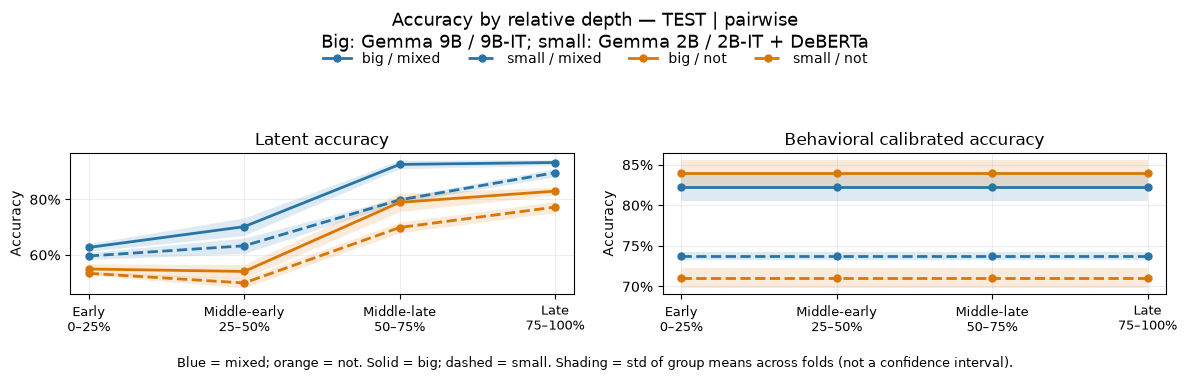

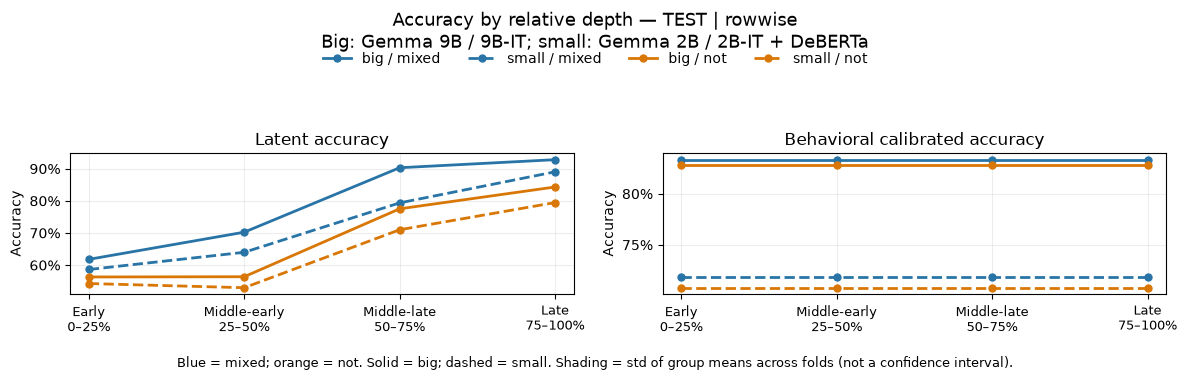

In [5]:
plots.aggregation(long, depth, OUTPUT_ROOT,
                  metrics=("latent_accuracy", "behavioral_accuracy"), splits=PLOT_SPLITS, smoke=not coverage.full_hyperparameters.all(),
                  calibrations=("calibrated",))

## Mismatch fractions

Доли усредняются в установленном порядке, без объединения строк mixed/not. Исходные количества и знаменатели сохраняются в модельных `metrics.csv`. Число sample × layer наблюдений не является числом уникальных текстов.

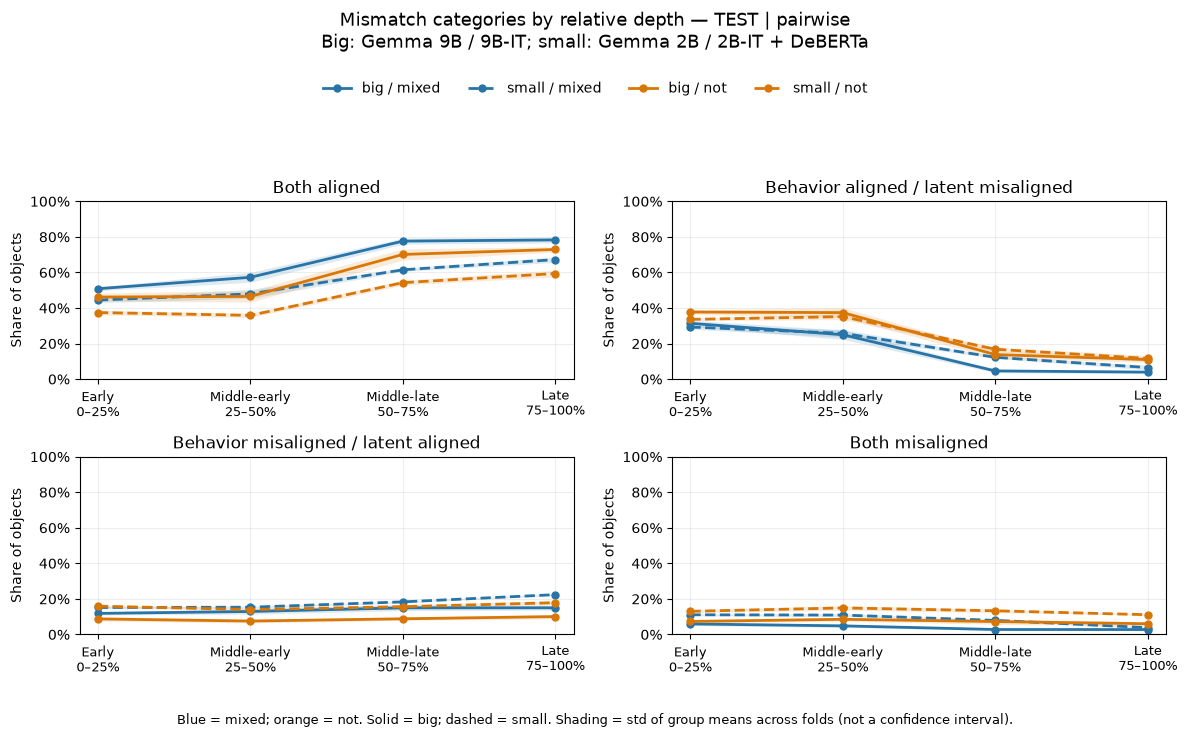

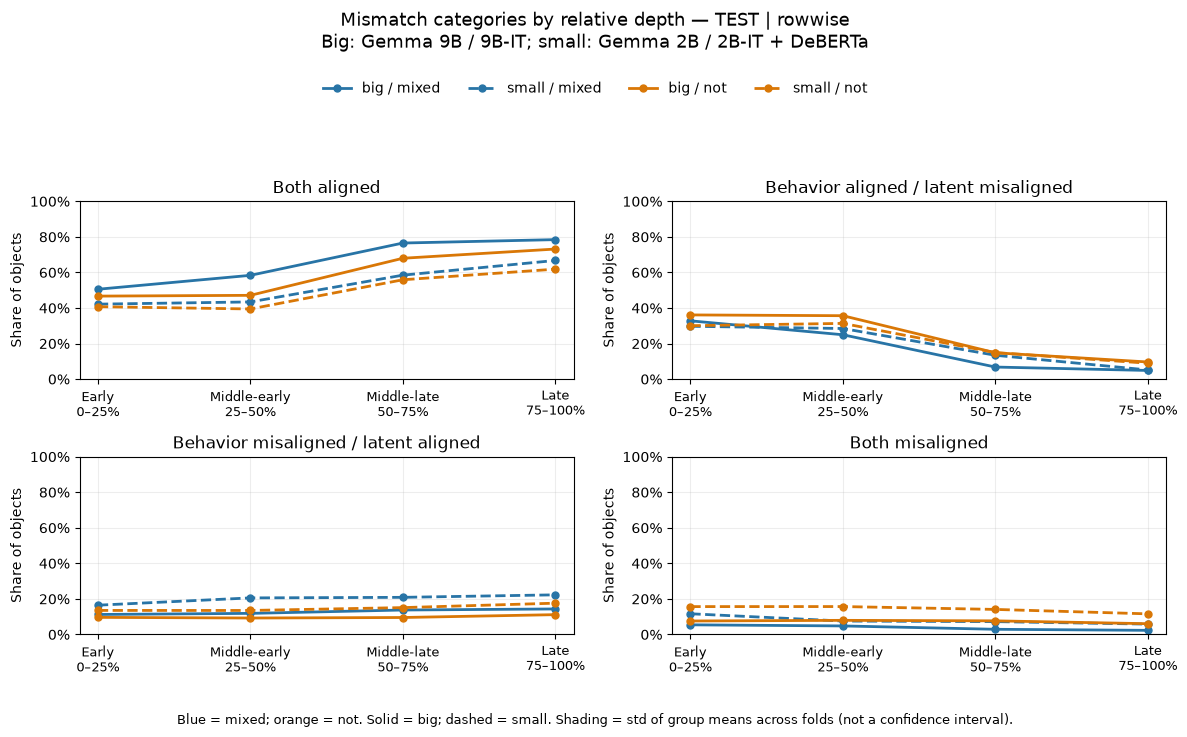

In [6]:
plots.aggregation(long, depth, OUTPUT_ROOT,
                  metrics=tuple(f"{case}_fraction" for case in CASES), splits=PLOT_SPLITS, smoke=not coverage.full_hyperparameters.all(),
                  calibrations=("calibrated",))

## PA-CCS reference и CCS-consistent

Каждый вариант остаётся самостоятельным измерением. Значения ESA в этом разделе относятся к выбранным PA-парам, не подменяя oriented latent accuracy.

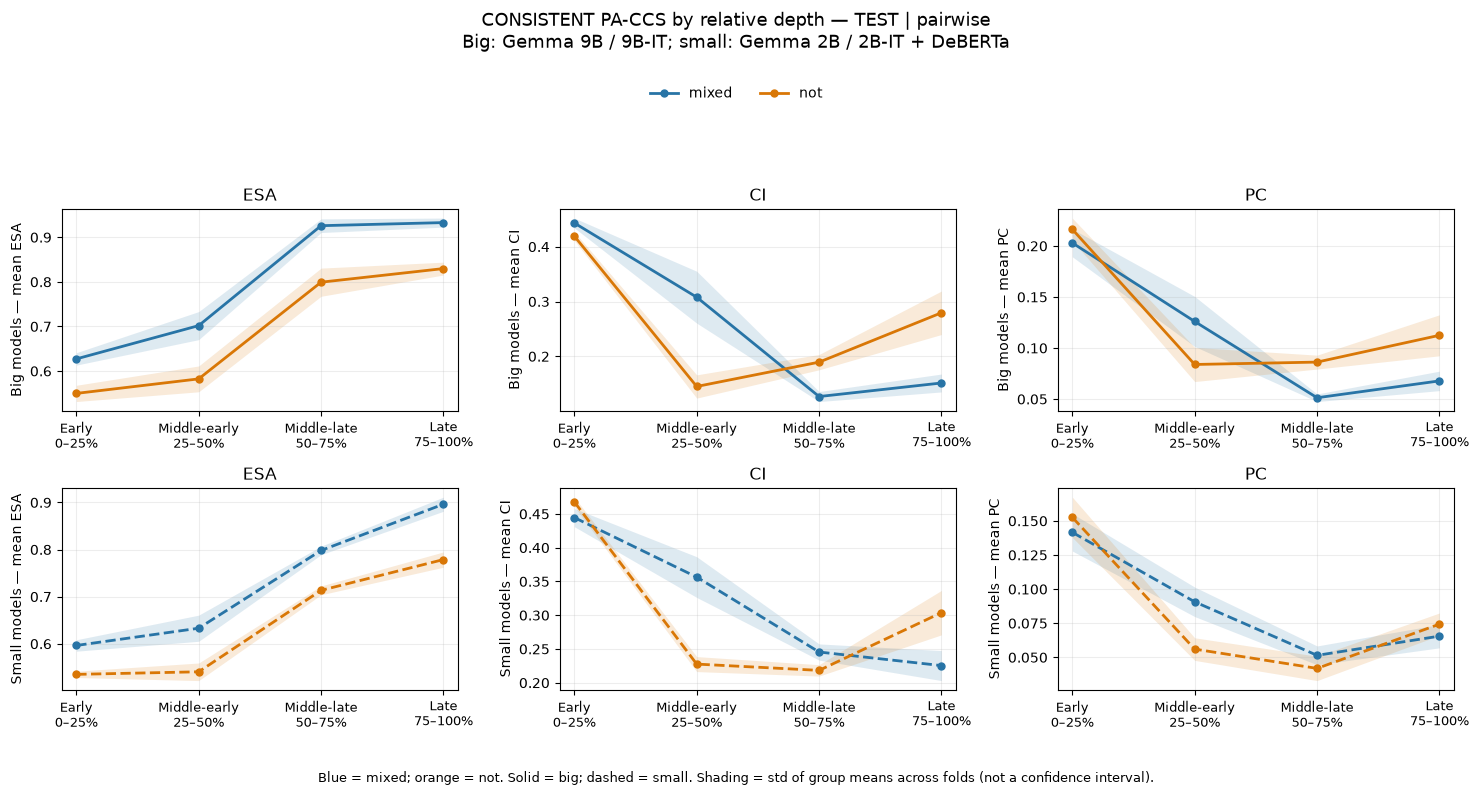

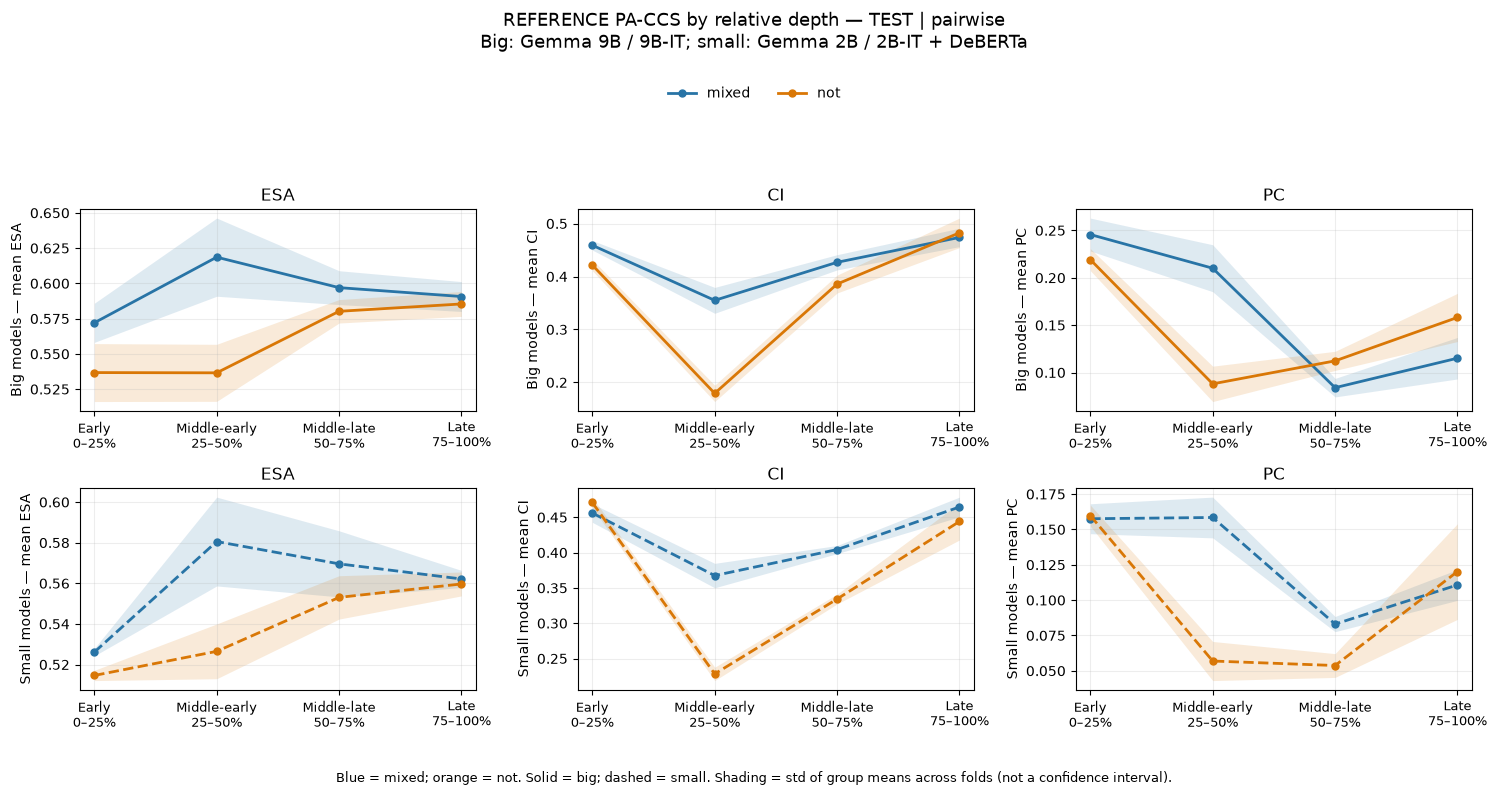

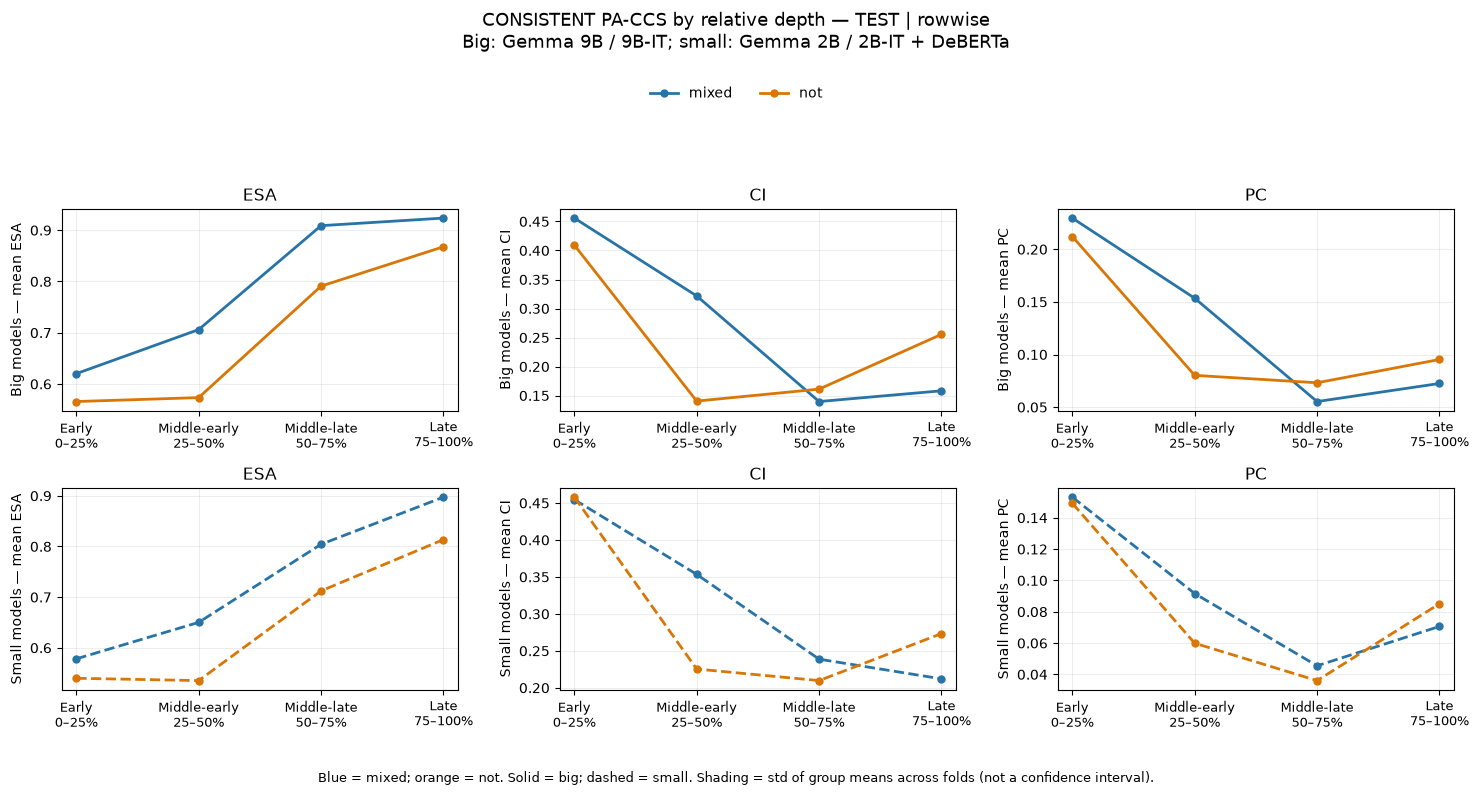

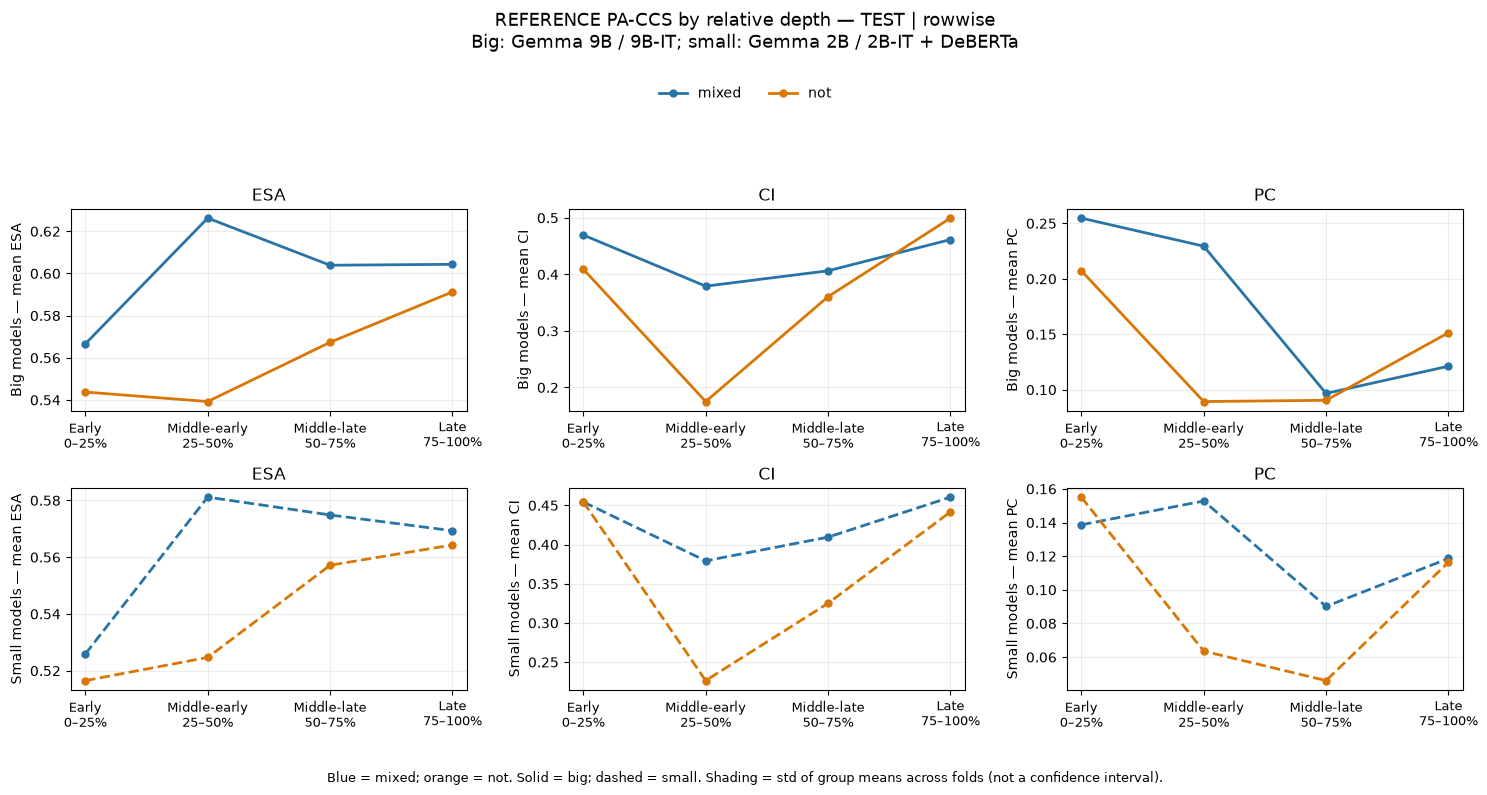

In [7]:
plots.aggregation(long, depth, OUTPUT_ROOT, metrics=("esa", "pc", "ci"),
                  splits=PLOT_SPLITS, smoke=not coverage.full_hyperparameters.all(), calibrations=("reference", "consistent"))

## Сохранённые результаты

Таблицы средних записаны отдельно в `aggregation/not/small`, `aggregation/not/big`, `aggregation/mixed/small`, `aggregation/mixed/big`. Общая таблица `model_layer_metrics.csv` хранит строки с обязательными dataset/model/protocol/split — она не является объединённой оценкой. Accuracy — два графика с четырьмя групповыми кривыми; mismatch — четыре категории в сетке 2×2; PA — ESA/CI/PC в сетке 2×3, big сверху и small снизу. Везде только четыре точки глубины и никаких отдельных моделей.

In [8]:
print(OUTPUT_ROOT / "aggregation")

/home/katyukh/projects/latent-behavior-alignment/results/model_experiments/saved_full/aggregation
